# Validação do Google Trends com o DataSenado

O painel de inadimplência (`inadimplencia_painel.ipynb`) deu nulo. Esse nulo só é informativo se o Google Trends
medir de fato **onde se aposta mais**. Aqui comparamos o Trends com uma medida direta: a pesquisa **DataSenado,
Panorama Político 2024** (coleta de 5 a 28/jun/2024, ~21.800 entrevistas, ~800 por UF), que perguntou se a pessoa
**gastou com apostas nos últimos 30 dias**.

Dados: `uv run python -m src.exposicao.datasenado`. Os números são extraídos do PDF oficial (Anexo 2, Tabelas 8 e 15),
porque os microdados não são abertos.

A mesma pesquisa permite um segundo teste, direto: **apostadores têm mais dívidas em atraso?**

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
from scipy import stats

from src.config import PROCESSED

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.float_format", "{:.3f}".format)

ds = pl.read_parquet(PROCESSED / "datasenado_uf_2024.parquet")
gt = pl.read_parquet(PROCESSED / "google_trends_uf.parquet").filter(pl.col("uf") != "BR")
g = gt.group_by("uf").agg(
    pl.col("indice_comparavel").filter(pl.col("data") == pl.date(2024, 6, 1)).mean().alias("trends_jun24"),
    pl.col("indice_comparavel").filter(pl.col("data").dt.year() == 2024).mean().alias("trends_2024"),
)
scr = (pl.read_parquet(PROCESSED / "scr_pf_uf_mes.parquet")
       .filter(pl.col("data_base").dt.strftime("%Y-%m") == "2024-06")
       .select("uf", pl.col("inad_pct").alias("scr_inad_jun24")))
d = ds.join(g, on="uf").join(scr, on="uf").to_pandas().set_index("uf")
d.sort_values("pct_apostou", ascending=False).head(10)

,pct_apostou,me_apostou,pct_divida90,me_divida90,trends_jun24,trends_2024,scr_inad_jun24
uf,,,,,,,
RR,17.000,3.700,38.000,5.400,123.398,116.328,4.122
PA,17.000,3.800,37.000,4.900,113.500,107.410,4.344
MT,17.000,5.600,34.000,5.200,112.384,108.610,2.363
AL,15.000,4.400,35.000,5.300,97.077,88.448,4.957
BA,14.000,3.700,35.000,5.200,127.958,113.296,4.810
TO,14.000,4.400,28.000,5.000,121.727,114.964,2.946
SE,14.000,3.800,36.000,5.900,105.897,99.033,4.276
RO,14.000,5.900,32.000,5.900,84.037,84.621,3.152
MA,14.000,4.000,35.000,6.900,139.024,130.182,4.424


## Decisões

**Qual Trends comparar.** Duas versões: o mês da pesquisa (**jun/2024**) e a **média de 2024**. A média do ano é a
mesma medida usada como exposição no painel (`trends_2024`) e é menos ruidosa, porque um único mês do Trends por UF
carrega muito ruído amostral do Google.

**Margem de erro.** O DataSenado reporta margem de erro por UF. Assumimos o padrão de 95% de confiança, ou seja,
erro-padrão = margem / 1,96. Os percentuais vêm **arredondados para inteiro**, o que soma um pouco de ruído
(variância ~1/12 p.p.², desprezível perto do erro amostral).

**Pesos.** Cada UF conta igual, porque a pergunta é se o Trends ordena bem as UFs.

**Pearson e Spearman.** Reportamos os dois. Com 27 pontos, um ou dois outliers mexem muito no Pearson; o Spearman
(postos) é mais robusto.

## 1. Quão confiável é o próprio DataSenado entre UFs?

Antes de usar o DataSenado como "verdade", precisamos saber quanto da variação dele entre UFs é real. Com ~800
entrevistas por UF, a margem de erro (±2 a ±6 p.p.) é do mesmo tamanho das diferenças entre UFs (8% a 17%).

**Confiabilidade** = variância real / variância observada = 1 − (variância do erro amostral / variância observada
entre UFs). Se for baixa, qualquer correlação com o DataSenado vai sair atenuada, mesmo que a outra medida seja perfeita.

In [2]:
def confiabilidade(pct, margem):
    v_obs = pct.var()
    v_err = ((margem / 1.96) ** 2).mean()
    return pd.Series({"variância observada": v_obs, "variância do erro amostral": v_err, "confiabilidade": (v_obs - v_err) / v_obs})

conf = pd.DataFrame({
    "% apostou (30 dias)": confiabilidade(d["pct_apostou"], d["me_apostou"]),
    "% dívida > 90 dias": confiabilidade(d["pct_divida90"], d["me_divida90"]),
}).T
conf

,variância observada,variância do erro amostral,confiabilidade
% apostou (30 dias),4.462,3.760,0.157
% dívida > 90 dias,17.447,7.576,0.566


**Leitura:** só **~16%** da variação do "% apostou" entre UFs é real. O resto é erro amostral. A prevalência de apostas
é bem parecida entre UFs (a maioria entre 11% e 14%), e a pesquisa não tem amostra suficiente por UF para separar
diferenças desse tamanho. Já o "% com dívida em atraso" é bem mais confiável (~57%).

## 2. Trends × DataSenado

A correlação observada com uma medida de confiabilidade *ρ* fica atenuada por um fator √ρ. A **correlação corrigida**
(correção de Spearman para atenuação) é `r_obs / √ρ`. Ela estima qual seria a correlação se o DataSenado não
tivesse erro amostral. Assumimos o Trends sem erro, então a correção é conservadora (o Trends também tem ruído).

In [3]:
def corr(a, b):
    r, p = stats.pearsonr(d[a], d[b]); s, ps = stats.spearmanr(d[a], d[b])
    return {"x": a, "y": b, "pearson": r, "p": p, "spearman": s, "p_spearman": ps}

rel_apostou = conf.loc["% apostou (30 dias)", "confiabilidade"]
tab = pd.DataFrame([corr("trends_jun24", "pct_apostou"), corr("trends_2024", "pct_apostou")])
tab["pearson_corrigido"] = (tab["pearson"] / np.sqrt(rel_apostou)).clip(upper=1)
tab

,x,y,pearson,p,spearman,p_spearman,pearson_corrigido
0,trends_jun24,pct_apostou,0.258,0.195,0.362,0.063,0.650
1,trends_2024,pct_apostou,0.307,0.119,0.431,0.025,0.775


Text(0.5, 1.0, 'Trends × DataSenado por UF (barras = margem de erro)')

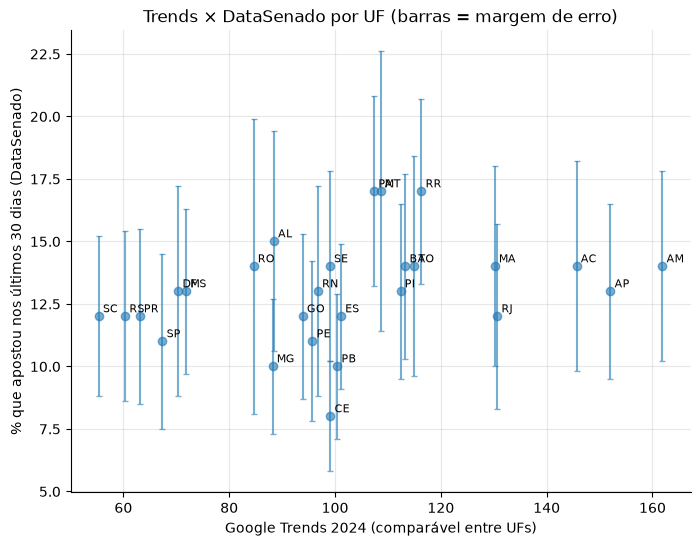

In [4]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.errorbar(d["trends_2024"], d["pct_apostou"], yerr=d["me_apostou"], fmt="o", alpha=0.6, capsize=2)
for uf, r in d.iterrows():
    ax.annotate(uf, (r["trends_2024"], r["pct_apostou"]), fontsize=8, xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("Google Trends 2024 (comparável entre UFs)"); ax.set_ylabel("% que apostou nos últimos 30 dias (DataSenado)")
ax.set_title("Trends × DataSenado por UF (barras = margem de erro)")

**Leitura:** a correlação observada é positiva e moderada (Spearman ~0,4 com o Trends de 2024, p ≈ 0,03). Depois de
corrigir pelo erro amostral do DataSenado, ela fica **alta (~0,8)**. Isso quer dizer que o Trends é **consistente**
com o DataSenado: dentro do que dá para medir, as duas fontes ordenam as UFs de forma parecida. Mas a validação é
fraca, porque o próprio DataSenado distingue mal as UFs. O que a figura mostra: barras de erro que se sobrepõem
quase todas.

**Implicação para o painel de inadimplência:** não há evidência de que o Trends seja uma medida ruim, então o nulo
do painel não parece ser só um problema de medida. Ele também usa variação **ao longo do tempo** dentro da UF, coisa
que esta validação de corte transversal não testa.

## 3. Apostas e dívidas: nível individual (nacional)

O relatório cruza apostadores com dívidas em atraso (Anexo 2, Tabelas 7 e 21):
- **32%** de toda a população tem dívida em atraso (Tabela 7).
- **42%** dos que apostaram nos últimos 30 dias têm dívida em atraso (Tabela 21, ±4,5 p.p.).
- Apostadores são **12%** da população (Tabela 15).

A taxa entre **não apostadores** sai por conta: `(32% − 12% × 42%) / 88%`.

⚠ **Inconsistência no relatório:** o título da Tabela 21 diz "atraso há mais de 90 dias", mas as linhas dizem
"há mais de **30** dias". Se for 30 dias, a comparação com os 32% (que são de 90 dias) superestima a diferença.

In [5]:
pop, aposta, div_apost = 0.32, 0.12, 0.42
div_nao = (pop - aposta * div_apost) / (1 - aposta)
pd.Series({"dívida em atraso — apostadores": div_apost, "dívida em atraso — não apostadores": div_nao,
           "diferença (p.p.)": (div_apost - div_nao) * 100, "razão": div_apost / div_nao})

dívida em atraso — apostadores        0.420
dívida em atraso — não apostadores    0.306
diferença (p.p.)                     11.364
razão                                 1.371
dtype: float64

**Leitura:** apostadores têm **~11 p.p. a mais** de dívida em atraso (42% contra ~31%, 1,4 vez). É a associação
negativa mais clara que temos, mas é **bruta**: apostadores são mais jovens, mais homens e de renda mais baixa
(Tabelas 16, 17 e 20 do relatório), e esses grupos já têm mais dívida independentemente de apostar. Sem os microdados
não dá para controlar por isso. Um pedido de LAI ao Senado resolveria: o relatório indica que os microdados existem.

## 4. Apostas e dívidas: nível de UF (ecológico)

In [6]:
pd.DataFrame([
    corr("pct_apostou", "pct_divida90"),
    corr("trends_2024", "pct_divida90"),
    corr("pct_apostou", "scr_inad_jun24"),
    corr("pct_divida90", "scr_inad_jun24"),
])

,x,y,pearson,p,spearman,p_spearman
0,pct_apostou,pct_divida90,0.279,0.159,0.331,0.092
1,trends_2024,pct_divida90,0.448,0.019,0.342,0.081
2,pct_apostou,scr_inad_jun24,-0.093,0.643,-0.010,0.961
3,pct_divida90,scr_inad_jun24,0.432,0.024,0.425,0.027


**Leitura:**
- **O SCR é validado pelo DataSenado.** A dívida em atraso que as pessoas declaram correlaciona com a inadimplência
  bancária do SCR (~0,43, p ≈ 0,02). As duas fontes medem algo parecido entre UFs.
- **Apostas × dívida entre UFs é fraco e positivo** (~0,3, não significativo com a medida do DataSenado; ~0,45,
  p ≈ 0,02 com o Trends × dívida declarada). Lembrando que é correlação ecológica de corte transversal: UFs mais pobres
  tendem a ter mais apostas *e* mais dívida, sem que uma cause a outra.
- **Com a inadimplência bancária do SCR, nada** (~0). Isso é coerente com o painel nulo e sugere que, se há dano,
  ele aparece mais em dívidas fora do sistema bancário (contas, crediário, informal), que entram na pergunta do
  DataSenado mas não no SCR.

## Resumo

1. O Trends é **consistente** com a prevalência de apostas medida pelo DataSenado (correlação corrigida ~0,8), mas a
   validação é fraca porque o DataSenado tem muito erro amostral por UF.
2. **No nível individual, apostadores têm mais dívida em atraso** (42% contra ~31%), sem controle por renda e idade.
3. **Entre UFs, apostas se associam a dívida declarada, mas não à inadimplência bancária.** A pista: o dano, se existe,
   pode estar em dívidas fora do SCR.

**Próximos passos:** pedir via LAI os microdados do DataSenado (para controlar renda, idade e sexo no cruzamento
apostador × dívida) e tentar de novo o Consumidor.gov.br, que estava fora do ar (504) em 07/11/2026.